# PROMPT #1

**Enunciado e instrucciones de la pregunta 1**

```text
tengo que usar prueba2_2026s2_acciones.csv solamente

retornos simples mensuales, no tasa libre de riesgo, para anualizar multiplicar media mensual por 12, desv estandar mensual por raiz de 12 y la varianza mensual por 12. spy se usa como mercado, no como una de las acciones.

1 
a. calcular retornos simples mensuales de las 10 acciones y con ellos el retorno promedio y desviacion estandar anualizados de cada una y grafique la relacion entre ambas variables en scactterplot.
i. cual es la accion mas riesgosa y la menos riesgosa.
ii. ¿hay acciones qe hayan sido dominantes o dominadas segin el criterio de media varianza durante este periodo? de dos ejemplos

b. calcular en el cuaderno la matriz de varianzas y covarianzas y la matriz de correlaciones de los retornos menusales.
en la hoja: i. cual es la correlacion promedio entre todos los pares de acciones? ii. ¿cual es la correlacion minima y la maxima y entre q acciones? ii. en funcion de los resultados ¿que espera en terminos de los beneficios de diversificacion alcanzables con estas acciones?

c. usando spy como mercado, descomponga en su cuaderno el riesgo de cada accion segun el capm sigma^2_i=beta^2_i*sigma^2_m+sigma^2_error de i. para cada accion obtenga beta_i. la varianza sistematica la idisincratica y el % de su varianza total que es idisincratico. puedo usar una rf casi constante solo con retornos de accion y spy, sin restarle la rf. el beta y % idiosincratico de las accoines con mayor y menor % idiosincratico, el % promedio de las 10 y conclusion

d. que espero encontrar entre el reotrno promedio de las accoines y su riesgo idiosincratico y por que. despues graficar el retorno promedio de c/ accion contr ariesgo idios. (desv. est. anualizada). ¿se cumplio prediccion? ¿hace sentido la relacion? relacionar con visto en clases.
```

In [1]:
from pathlib import Path
import urllib.request
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

pd.options.display.float_format = "{:,.6f}".format
plt.rcParams.update({"figure.figsize": (9, 6), "axes.grid": True, "grid.alpha": 0.25})

In [2]:
NOMBRE_CSV = "Prueba2_2026S2_acciones.csv"
REVISION = "80fb1dc276e281dffbd8e299e2ab8bb09ea1c965"
HASH_CSV = "df17552470653dbe083b64fca155051ee563ff33703288490d84c0a4a4368e72"
URL_CSV = f"https://raw.githubusercontent.com/eldiegoveliz/AssetPricing-P2/{REVISION}/{NOMBRE_CSV}"

# Admite el nombre original y la misma escritura en minúsculas al subir el archivo.
carpetas = [Path.cwd(), Path.cwd() / "datos", Path("/workspace/AssetPricing-P2")]
candidatos = [carpeta / nombre for carpeta in carpetas for nombre in [NOMBRE_CSV, NOMBRE_CSV.lower()]]
ruta_csv = next((p for p in candidatos if p.is_file()), None)
if ruta_csv is None:
    with urllib.request.urlopen(URL_CSV, timeout=45) as respuesta:
        contenido = respuesta.read()
    if hashlib.sha256(contenido).hexdigest() != HASH_CSV:
        raise ValueError("La descarga no coincide con el archivo original. Revisa la fuente.")
    ruta_csv = Path(NOMBRE_CSV)
    ruta_csv.write_bytes(contenido)

if hashlib.sha256(ruta_csv.read_bytes()).hexdigest() != HASH_CSV:
    raise ValueError("El CSV difiere del archivo original del repositorio usado para esta pregunta. Revisa el dato.")

precios = pd.read_csv(ruta_csv, parse_dates=["Date"]).set_index("Date").sort_index()
ACCIONES = ["AAPL", "JPM", "XOM", "JNJ", "PG", "HD", "CAT", "NEE", "VZ", "SHW"]
assert set(precios.columns) == set(ACCIONES + ["SPY"])
assert precios.index.is_unique and precios.index.notna().all()
assert precios.notna().all().all() and (precios > 0).all().all()
assert precios.index.to_period("M").is_unique
assert np.all(np.diff(precios.index.to_period("M").asi8) == 1), "Hay meses faltantes."

# El primer precio no produce un retorno. No se rellenan precios ni retornos.
retornos = precios.pct_change(fill_method=None).iloc[1:]
R = retornos[ACCIONES].copy()
mercado = retornos["SPY"].copy()
assert R.notna().all().all() and mercado.notna().all()
assert R.shape[1] == 10 and "SPY" not in R.columns
T = len(R)
print(f"{len(precios)} precios mensuales; {T} retornos mensuales por serie.")
print(f"Retornos: {R.index.min().date()} a {R.index.max().date()}.")
print("Diez acciones:", ", ".join(ACCIONES), "| Mercado: SPY")
display(R.head())

121 precios mensuales; 120 retornos mensuales por serie.
Retornos: 2016-01-31 a 2025-12-31.
Diez acciones: AAPL, JPM, XOM, JNJ, PG, HD, CAT, NEE, VZ, SHW | Mercado: SPY


,AAPL,JPM,XOM,JNJ,PG,HD,CAT,NEE,VZ,SHW
Date,,,,,,,,,,
2016-01-31,-0.075240,-0.092849,-0.001284,0.016745,0.037679,-0.049074,-0.072701,0.075271,0.094432,-0.015138
2016-02-29,-0.001288,-0.053782,0.038888,0.014672,-0.017138,-0.013041,0.087725,0.017562,0.015210,0.061438
2016-03-31,0.127208,0.051866,0.042921,0.028419,0.025159,0.080920,0.130577,0.048925,0.066037,0.052384
2016-04-30,-0.139918,0.075108,0.057543,0.035860,-0.018633,0.003447,0.025317,-0.006420,-0.048119,0.009274
2016-05-31,0.071771,0.032753,0.015477,0.012620,0.011483,-0.008110,-0.067036,0.029118,-0.000786,0.016072


,retorno_promedio_mensual_pct,desv_estandar_mensual_pct,retorno_promedio_anual_pct,desv_estandar_anual_pct
accion,,,,
AAPL,2.361900,7.947900,28.342900,27.532200
JPM,1.801900,7.015000,21.622800,24.300600
XOM,1.031100,7.837800,12.373800,27.150800
JNJ,0.928100,4.729700,11.137500,16.384000
PG,0.828800,4.618700,9.945600,15.999700
HD,1.203700,6.417600,14.444500,22.231200
CAT,2.363400,8.655700,28.361300,29.984100
NEE,1.346400,6.111700,16.156200,21.171500
VZ,0.463700,5.198200,5.564700,18.007100


a.i — Mayor riesgo total: CAT, desviación anual = 29.9841%.
a.i — Menor riesgo total: PG, desviación anual = 15.9997%.


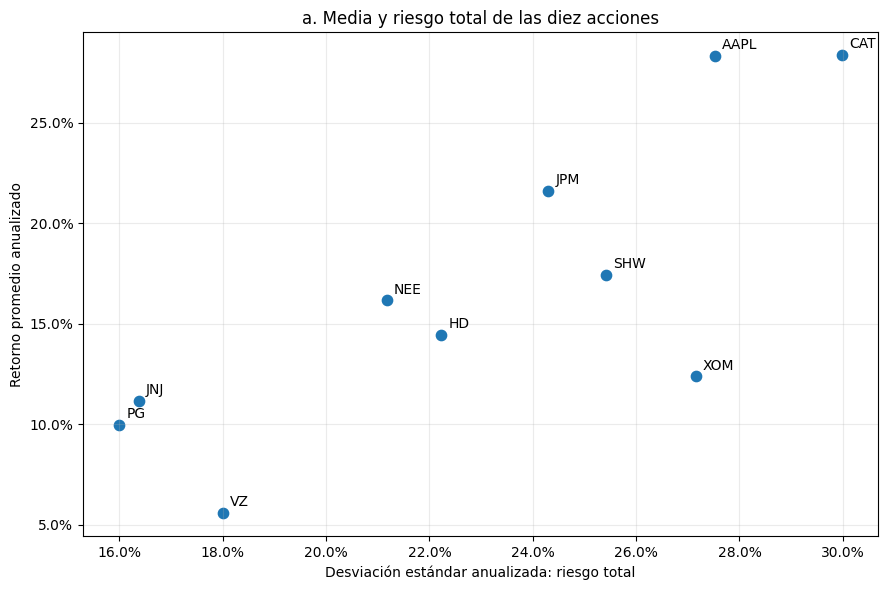

In [3]:
media_mensual = R.mean()
desv_mensual = R.std(ddof=1)
media_anual = media_mensual * 12
desv_anual = desv_mensual * np.sqrt(12)

tabla_a = pd.DataFrame({
    "retorno_promedio_mensual_pct": 100 * media_mensual,
    "desv_estandar_mensual_pct": 100 * desv_mensual,
    "retorno_promedio_anual_pct": 100 * media_anual,
    "desv_estandar_anual_pct": 100 * desv_anual,
})
tabla_a.index.name = "accion"
display(tabla_a.round(4))

mas_riesgosa = desv_anual.idxmax()
menos_riesgosa = desv_anual.idxmin()
print(f"a.i — Mayor riesgo total: {mas_riesgosa}, desviación anual = {desv_anual[mas_riesgosa]:.4%}.")
print(f"a.i — Menor riesgo total: {menos_riesgosa}, desviación anual = {desv_anual[menos_riesgosa]:.4%}.")

fig, ax = plt.subplots()
ax.scatter(desv_anual, media_anual, s=55)
for accion in ACCIONES:
    ax.annotate(accion, (desv_anual[accion], media_anual[accion]), xytext=(5, 5), textcoords="offset points")
ax.set(xlabel="Desviación estándar anualizada: riesgo total", ylabel="Retorno promedio anualizado",
       title="a. Media y riesgo total de las diez acciones")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout()
plt.show()

In [4]:
filas_dominancia = []
for a in ACCIONES:
    for b in ACCIONES:
        if a == b:
            continue
        domina = ((media_anual[a] >= media_anual[b]) and (desv_anual[a] <= desv_anual[b])
                  and ((media_anual[a] > media_anual[b]) or (desv_anual[a] < desv_anual[b])))
        if domina:
            filas_dominancia.append({
                "dominante": a, "dominada": b,
                "media_dominante_anual_pct": 100 * media_anual[a],
                "media_dominada_anual_pct": 100 * media_anual[b],
                "desv_dominante_anual_pct": 100 * desv_anual[a],
                "desv_dominada_anual_pct": 100 * desv_anual[b],
            })
tabla_dominancia = pd.DataFrame(filas_dominancia)
display(tabla_dominancia.round(4))
if not tabla_dominancia.empty:
    dominadas = set(tabla_dominancia["dominada"])
    no_dominadas = [a for a in ACCIONES if a not in dominadas]
    print("a.ii — Dos ejemplos calculados:")
    for _, fila in tabla_dominancia.head(2).iterrows():
        print(f"{fila['dominante']} domina a {fila['dominada']}: "
              f"media {fila['media_dominante_anual_pct']:.4f}% frente a {fila['media_dominada_anual_pct']:.4f}%; "
              f"desviación {fila['desv_dominante_anual_pct']:.4f}% frente a {fila['desv_dominada_anual_pct']:.4f}%.")
    print("No dominadas por otra acción individual:", no_dominadas)
else:
    print("No hay dominancia entre acciones individuales en esta muestra.")

,dominante,dominada,media_dominante_anual_pct,media_dominada_anual_pct,desv_dominante_anual_pct,desv_dominada_anual_pct
0,JPM,XOM,21.622800,12.373800,24.300600,27.150800
1,JPM,SHW,21.622800,17.420800,24.300600,25.411600
2,JNJ,VZ,11.137500,5.564700,16.384000,18.007100
3,PG,VZ,9.945600,5.564700,15.999700,18.007100
4,HD,XOM,14.444500,12.373800,22.231200,27.150800
5,NEE,XOM,16.156200,12.373800,21.171500,27.150800
6,NEE,HD,16.156200,14.444500,21.171500,22.231200
7,SHW,XOM,17.420800,12.373800,25.411600,27.150800


a.ii — Dos ejemplos calculados:
JPM domina a XOM: media 21.6228% frente a 12.3738%; desviación 24.3006% frente a 27.1508%.
JPM domina a SHW: media 21.6228% frente a 17.4208%; desviación 24.3006% frente a 25.4116%.
No dominadas por otra acción individual: ['AAPL', 'JPM', 'JNJ', 'PG', 'CAT', 'NEE']


In [5]:
cov_mensual = R.cov(ddof=1)
corr_mensual = R.corr()
print("Matriz de varianzas y covarianzas MENSUALES, retornos en decimales:")
display(cov_mensual)
print("Matriz de correlaciones de retornos MENSUALES:")
display(corr_mensual)

pares = pd.DataFrame([
    {"accion_1": a, "accion_2": b, "correlacion": corr_mensual.loc[a, b]}
    for i, a in enumerate(ACCIONES) for b in ACCIONES[i + 1:]
])
assert len(pares) == 45
correlacion_promedio = pares["correlacion"].mean()
par_minimo = pares.loc[pares["correlacion"].idxmin()]
par_maximo = pares.loc[pares["correlacion"].idxmax()]
print(f"b.i — Correlación promedio de {len(pares)} pares únicos: {correlacion_promedio:.6f}")
print(f"b.ii — Mínima: {par_minimo['correlacion']:.6f}, entre {par_minimo['accion_1']} y {par_minimo['accion_2']}.")
print(f"b.ii — Máxima: {par_maximo['correlacion']:.6f}, entre {par_maximo['accion_1']} y {par_maximo['accion_2']}.")
display(pares.sort_values("correlacion").reset_index(drop=True))

Matriz de varianzas y covarianzas MENSUALES, retornos en decimales:


accion,AAPL,JPM,XOM,JNJ,PG,HD,CAT,NEE,VZ,SHW
accion,,,,,,,,,,
AAPL,0.006317,0.001500,0.000999,0.001239,0.001048,0.002005,0.001699,0.001373,0.000444,0.002141
JPM,0.001500,0.004921,0.002785,0.001140,0.000480,0.002102,0.003477,0.000386,0.000679,0.002559
XOM,0.000999,0.002785,0.006143,0.001371,0.000488,0.001393,0.003016,-0.000253,0.001168,0.001399
JNJ,0.001239,0.001140,0.001371,0.002237,0.000901,0.001069,0.001407,0.000895,0.000953,0.001521
PG,0.001048,0.000480,0.000488,0.000901,0.002133,0.001164,0.000543,0.000881,0.001118,0.001590
HD,0.002005,0.002102,0.001393,0.001069,0.001164,0.004119,0.002563,0.000905,0.000920,0.003683
CAT,0.001699,0.003477,0.003016,0.001407,0.000543,0.002563,0.007492,0.000760,0.000452,0.003252
NEE,0.001373,0.000386,-0.000253,0.000895,0.000881,0.000905,0.000760,0.003735,0.000794,0.001258
VZ,0.000444,0.000679,0.001168,0.000953,0.001118,0.000920,0.000452,0.000794,0.002702,0.000888


Matriz de correlaciones de retornos MENSUALES:


accion,AAPL,JPM,XOM,JNJ,PG,HD,CAT,NEE,VZ,SHW
accion,,,,,,,,,,
AAPL,1.000000,0.268974,0.160440,0.329616,0.285519,0.393170,0.246914,0.282691,0.107536,0.367249
JPM,0.268974,1.000000,0.506539,0.343609,0.148204,0.466988,0.572567,0.089935,0.186148,0.497316
XOM,0.160440,0.506539,1.000000,0.369734,0.134778,0.276971,0.444628,-0.052752,0.286738,0.243401
JNJ,0.329616,0.343609,0.369734,1.000000,0.412638,0.352308,0.343731,0.309624,0.387654,0.438281
PG,0.285519,0.148204,0.134778,0.412638,1.000000,0.392733,0.135904,0.312009,0.465866,0.469289
HD,0.393170,0.466988,0.276971,0.352308,0.392733,1.000000,0.461331,0.230611,0.275891,0.782237
CAT,0.246914,0.572567,0.444628,0.343731,0.135904,0.461331,1.000000,0.143717,0.100500,0.512120
NEE,0.282691,0.089935,-0.052752,0.309624,0.312009,0.230611,0.143717,1.000000,0.250001,0.280679
VZ,0.107536,0.186148,0.286738,0.387654,0.465866,0.275891,0.100500,0.250001,1.000000,0.232996


b.i — Correlación promedio de 45 pares únicos: 0.316601
b.ii — Mínima: -0.052752, entre XOM y NEE.
b.ii — Máxima: 0.782237, entre HD y SHW.


,accion_1,accion_2,correlacion
0,XOM,NEE,-0.052752
1,JPM,NEE,0.089935
2,CAT,VZ,0.100500
3,AAPL,VZ,0.107536
4,XOM,PG,0.134778
5,PG,CAT,0.135904
6,CAT,NEE,0.143717
7,JPM,PG,0.148204
8,AAPL,XOM,0.160440
9,JPM,VZ,0.186148


In [6]:
# OLS vectorial de las diez acciones con intercepto. Sin tasa libre de riesgo.
X = np.column_stack([np.ones(T), mercado.to_numpy()])
Y = R.to_numpy()
coeficientes = np.linalg.lstsq(X, Y, rcond=None)[0]
interceptos = pd.Series(coeficientes[0], index=ACCIONES)
betas = pd.Series(coeficientes[1], index=ACCIONES, name="beta")
residuos = pd.DataFrame(Y - X @ coeficientes, index=R.index, columns=ACCIONES)

var_mercado_m = mercado.var(ddof=1)
var_total_m = R.var(ddof=1)
var_sist_m = betas.pow(2) * var_mercado_m
var_idio_m = residuos.var(ddof=1)
porcentaje_idio = 100 * var_idio_m / var_total_m

assert np.allclose(var_total_m, var_sist_m + var_idio_m, rtol=1e-10, atol=1e-12)
assert np.allclose(betas, R.apply(lambda serie: serie.cov(mercado)) / var_mercado_m)
assert np.allclose(residuos.mean(), 0, atol=1e-12)
assert np.allclose(residuos.apply(lambda serie: serie.cov(mercado)), 0, atol=1e-12)

tabla_c_mensual = pd.DataFrame({
    "beta": betas, "var_total_mensual": var_total_m,
    "var_sistematica_mensual": var_sist_m, "var_idiosincratica_mensual": var_idio_m,
    "porcentaje_varianza_idiosincratica": porcentaje_idio,
})
tabla_c_anual = pd.DataFrame({
    "beta": betas, "var_total_anual": var_total_m * 12,
    "var_sistematica_anual": var_sist_m * 12, "var_idiosincratica_anual": var_idio_m * 12,
    "porcentaje_varianza_idiosincratica": porcentaje_idio,
})
tabla_c_mensual.index.name = tabla_c_anual.index.name = "accion"
print("Descomposición MENSUAL; varianzas en unidades de retorno decimal al cuadrado:")
display(tabla_c_mensual)
print("La misma descomposición ANUALIZADA; varianzas mensuales × 12:")
display(tabla_c_anual)

mayor_idio = porcentaje_idio.idxmax()
menor_idio = porcentaje_idio.idxmin()
promedio_porcentaje_idio = porcentaje_idio.mean()  # Media simple de los diez porcentajes, no un cociente de sumas.
print(f"c — Mayor % idiosincrático: {mayor_idio}; beta = {betas[mayor_idio]:.6f}; % idio = {porcentaje_idio[mayor_idio]:.4f}%.")
print(f"c — Menor % idiosincrático: {menor_idio}; beta = {betas[menor_idio]:.6f}; % idio = {porcentaje_idio[menor_idio]:.4f}%.")
print(f"c — Promedio simple del % idiosincrático de las diez acciones: {promedio_porcentaje_idio:.4f}%.")
print("Identidad verificada: var_total = var_sistemática + var_idiosincrática para cada acción.")

Descomposición MENSUAL; varianzas en unidades de retorno decimal al cuadrado:


,beta,var_total_mensual,var_sistematica_mensual,var_idiosincratica_mensual,porcentaje_varianza_idiosincratica
accion,,,,,
AAPL,1.191449,0.006317,0.002691,0.003626,57.402388
JPM,1.158572,0.004921,0.002544,0.002377,48.295748
XOM,0.874496,0.006143,0.001450,0.004693,76.402528
JNJ,0.520855,0.002237,0.000514,0.001723,77.011691
PG,0.388141,0.002133,0.000286,0.001848,86.613428
HD,1.055734,0.004119,0.002113,0.002006,48.702204
CAT,1.276780,0.007492,0.003090,0.004402,58.755570
NEE,0.456098,0.003735,0.000394,0.003341,89.443260
VZ,0.374657,0.002702,0.000266,0.002436,90.153162


La misma descomposición ANUALIZADA; varianzas mensuales × 12:


,beta,var_total_anual,var_sistematica_anual,var_idiosincratica_anual,porcentaje_varianza_idiosincratica
accion,,,,,
AAPL,1.191449,0.075802,0.032290,0.043512,57.402388
JPM,1.158572,0.059052,0.030532,0.028520,48.295748
XOM,0.874496,0.073717,0.017395,0.056321,76.402528
JNJ,0.520855,0.026844,0.006171,0.020673,77.011691
PG,0.388141,0.025599,0.003427,0.022172,86.613428
HD,1.055734,0.049423,0.025353,0.024070,48.702204
CAT,1.276780,0.089905,0.037081,0.052824,58.755570
NEE,0.456098,0.044823,0.004732,0.040091,89.443260
VZ,0.374657,0.032426,0.003193,0.029233,90.153162


c — Mayor % idiosincrático: VZ; beta = 0.374657; % idio = 90.1532%.
c — Menor % idiosincrático: JPM; beta = 1.158572; % idio = 48.2957%.
c — Promedio simple del % idiosincrático de las diez acciones: 68.7042%.
Identidad verificada: var_total = var_sistemática + var_idiosincrática para cada acción.


,retorno_promedio_anual_pct,desv_idiosincratica_anual_pct,porcentaje_varianza_idiosincratica
accion,,,
AAPL,28.342900,20.859600,57.402400
JPM,21.622800,16.887800,48.295700
XOM,12.373800,23.732100,76.402500
JNJ,11.137500,14.378000,77.011700
PG,9.945600,14.890400,86.613400
HD,14.444500,15.514500,48.702200
CAT,28.361300,22.983500,58.755600
NEE,16.156200,20.022800,89.443300
VZ,5.564700,17.097600,90.153200


Correlación descriptiva entre las diez medias y sus desviaciones idiosincráticas: 0.520787.


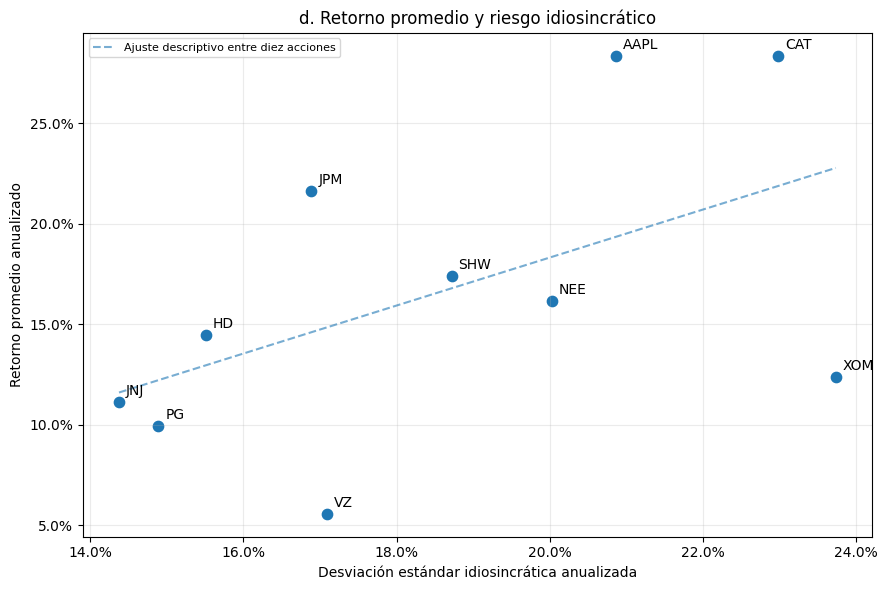

In [7]:
desv_idio_anual = np.sqrt(var_idio_m * 12)
tabla_d = pd.DataFrame({
    "retorno_promedio_anual_pct": 100 * media_anual,
    "desv_idiosincratica_anual_pct": 100 * desv_idio_anual,
    "porcentaje_varianza_idiosincratica": porcentaje_idio,
})
tabla_d.index.name = "accion"
display(tabla_d.round(4))

correlacion_retorno_idio = media_anual.corr(desv_idio_anual)
print(f"Correlación descriptiva entre las diez medias y sus desviaciones idiosincráticas: {correlacion_retorno_idio:.6f}.")
fig, ax = plt.subplots()
ax.scatter(desv_idio_anual, media_anual, s=55)
for accion in ACCIONES:
    ax.annotate(accion, (desv_idio_anual[accion], media_anual[accion]), xytext=(5, 5), textcoords="offset points")
# Recta únicamente descriptiva; no es una relación de valorización ni un efecto causal.
pendiente, constante = np.polyfit(desv_idio_anual, media_anual, 1)
xx = np.linspace(desv_idio_anual.min(), desv_idio_anual.max(), 100)
ax.plot(xx, constante + pendiente * xx, "--", alpha=0.6, label="Ajuste descriptivo entre diez acciones")
ax.set(xlabel="Desviación estándar idiosincrática anualizada", ylabel="Retorno promedio anualizado",
       title="d. Retorno promedio y riesgo idiosincrático")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [8]:
assert T == 120 and len(ACCIONES) == 10
assert np.allclose(np.diag(cov_mensual), var_total_m)
assert np.allclose(desv_anual.pow(2), var_total_m * 12)
assert np.allclose(tabla_c_anual["var_total_anual"],
                   tabla_c_anual["var_sistematica_anual"] + tabla_c_anual["var_idiosincratica_anual"])
R2 = 1 - residuos.pow(2).sum() / ((R - R.mean()).pow(2).sum())
assert np.allclose(porcentaje_idio / 100, 1 - R2)
assert porcentaje_idio.between(0, 100).all()
assert len(pares) == 45 and (pares["accion_1"] != pares["accion_2"]).all()

carpeta_resultados = Path("resultados_pregunta1")
carpeta_resultados.mkdir(exist_ok=True)
tablas = {
    "a_retornos_y_riesgo": tabla_a, "a_dominancia": tabla_dominancia,
    "b_covarianzas_mensuales": cov_mensual, "b_correlaciones_mensuales": corr_mensual,
    "b_45_pares": pares, "c_descomposicion_mensual": tabla_c_mensual,
    "c_descomposicion_anual": tabla_c_anual, "d_retorno_y_riesgo_idiosincratico": tabla_d,
    "retornos_simples_mensuales_10_acciones": R,
}
for nombre, tabla in tablas.items():
    tabla.to_csv(carpeta_resultados / f"{nombre}.csv", encoding="utf-8-sig")
print("Controles: OK. Exportadas", len(tablas), "tablas a resultados_pregunta1/.")
print("No se usó tasa libre de riesgo ni ningún otro archivo de datos.")

Controles: OK. Exportadas 9 tablas a resultados_pregunta1/.
No se usó tasa libre de riesgo ni ningún otro archivo de datos.


In [9]:
from IPython.display import Markdown

display(Markdown(f"""
**1.a.i.** La acción más riesgosa es **{mas_riesgosa}**, con desviación estándar anualizada de
**{desv_anual[mas_riesgosa]:.4%}**; la menos riesgosa es **{menos_riesgosa}**, con **{desv_anual[menos_riesgosa]:.4%}**.

**1.a.ii. Dos ejemplos de dominancia media-varianza:**
- **JPM domina a XOM**: retorno medio anualizado {media_anual['JPM']:.4%} frente a {media_anual['XOM']:.4%},
  y desviación anualizada {desv_anual['JPM']:.4%} frente a {desv_anual['XOM']:.4%}.
- **NEE domina a HD**: retorno medio anualizado {media_anual['NEE']:.4%} frente a {media_anual['HD']:.4%},
  y desviación anualizada {desv_anual['NEE']:.4%} frente a {desv_anual['HD']:.4%}.
En ambos casos la dominante tiene mayor media y menor desviación en este período.

**1.b.** La correlación promedio de los 45 pares únicos es **{correlacion_promedio:.6f}**.
La mínima es **{par_minimo['correlacion']:.6f}**, entre **{par_minimo['accion_1']} y {par_minimo['accion_2']}**;
la máxima es **{par_maximo['correlacion']:.6f}**, entre **{par_maximo['accion_1']} y {par_maximo['accion_2']}**.
Las correlaciones inferiores a uno permiten reducir riesgo mediante combinaciones de activos. Los beneficios
son potencialmente mayores para pares con menor correlación, dadas sus volatilidades y sus pesos. No se
elimina el riesgo común ni se garantiza que todas las combinaciones sean menos riesgosas que cada acción.

**1.c.** El mayor porcentaje idiosincrático corresponde a **{mayor_idio}**, con beta **{betas[mayor_idio]:.6f}**
y **{porcentaje_idio[mayor_idio]:.4f}%** de su varianza. El menor corresponde a **{menor_idio}**, con beta
**{betas[menor_idio]:.6f}** y **{porcentaje_idio[menor_idio]:.4f}%**. La media simple de los diez porcentajes
es **{promedio_porcentaje_idio:.4f}%**. Una parte relevante de la varianza individual queda sin explicar por SPY;
la diversificación puede reducirla si los residuos no están perfectamente correlacionados. Esto no equivale
al porcentaje idiosincrático de una cartera, y el residuo puede incluir factores comunes omitidos.

**1.d.** Según CAPM, el riesgo idiosincrático es diversificable y no recibe una prima independiente:
el riesgo remunerado es la exposición sistemática. En el gráfico se observa una asociación positiva entre
las medias históricas y las desviaciones idiosincráticas, con correlación **{correlacion_retorno_idio:.6f}**.
Por tanto, el gráfico no muestra ausencia de asociación bruta ni reproduce la dirección negativa de la anomalía
de baja volatilidad idiosincrática discutida en clases. Sin embargo, esa asociación no demuestra que se
remunere el riesgo idiosincrático ni rechaza CAPM: son diez medias realizadas, sin controlar beta u otros factores,
y la teoría no exige que la correlación bruta sea exactamente cero. El contraste con la evidencia de clases
debe considerar sus universos, períodos y métodos distintos.
"""))


**1.a.i.** La acción más riesgosa es **CAT**, con desviación estándar anualizada de
**29.9841%**; la menos riesgosa es **PG**, con **15.9997%**.

**1.a.ii. Dos ejemplos de dominancia media-varianza:**
- **JPM domina a XOM**: retorno medio anualizado 21.6228% frente a 12.3738%,
  y desviación anualizada 24.3006% frente a 27.1508%.
- **NEE domina a HD**: retorno medio anualizado 16.1562% frente a 14.4445%,
  y desviación anualizada 21.1715% frente a 22.2312%.
En ambos casos la dominante tiene mayor media y menor desviación en este período.

**1.b.** La correlación promedio de los 45 pares únicos es **0.316601**.
La mínima es **-0.052752**, entre **XOM y NEE**;
la máxima es **0.782237**, entre **HD y SHW**.
Las correlaciones inferiores a uno permiten reducir riesgo mediante combinaciones de activos. Los beneficios
son potencialmente mayores para pares con menor correlación, dadas sus volatilidades y sus pesos. No se
elimina el riesgo común ni se garantiza que todas las combinaciones sean menos riesgosas que cada acción.

**1.c.** El mayor porcentaje idiosincrático corresponde a **VZ**, con beta **0.374657**
y **90.1532%** de su varianza. El menor corresponde a **JPM**, con beta
**1.158572** y **48.2957%**. La media simple de los diez porcentajes
es **68.7042%**. Una parte relevante de la varianza individual queda sin explicar por SPY;
la diversificación puede reducirla si los residuos no están perfectamente correlacionados. Esto no equivale
al porcentaje idiosincrático de una cartera, y el residuo puede incluir factores comunes omitidos.

**1.d.** Según CAPM, el riesgo idiosincrático es diversificable y no recibe una prima independiente:
el riesgo remunerado es la exposición sistemática. En el gráfico se observa una asociación positiva entre
las medias históricas y las desviaciones idiosincráticas, con correlación **0.520787**.
Por tanto, el gráfico no muestra ausencia de asociación bruta ni reproduce la dirección negativa de la anomalía
de baja volatilidad idiosincrática discutida en clases. Sin embargo, esa asociación no demuestra que se
remunere el riesgo idiosincrático ni rechaza CAPM: son diez medias realizadas, sin controlar beta u otros factores,
y la teoría no exige que la correlación bruta sea exactamente cero. El contraste con la evidencia de clases
debe considerar sus universos, períodos y métodos distintos.


# PROMPT #2

**Enunciado de la pregunta 2 e instrucción de integrar ambas preguntas en un cuaderno**

```text
pregunta 2. 

divida la muestra en dos mitades los primeros 60 meses enero 2016 a 2020-12 para estimar y los ultimos 60 2021-01 a 2025-12 para evaluar. solo las 10 acciones.

a. con la matriz de covarianzas de la primera mitad calcular los pesos de la cartera de minima varianza global sin restricciones en la hoja indique cuantas posiciones cortas y comenteacerca de implementacion. practica.
b. calcule la desviacion estandar anualizada de la cartera de minima varianza y de la cartera 1/N en cada mitad ¿q observa?
c. un cliente pregunta si incertir 1/N o minima var. ¿q recomienda? indicar que no puedo afirmar con esos resultados.


---- necesito las dos preguntas en un ipynb. commit and push esa version completa para entrega
```

In [10]:
p2_estimacion = R.loc["2016-01-01":"2020-12-31"].copy()
p2_evaluacion = R.loc["2021-01-01":"2025-12-31"].copy()
assert p2_estimacion.shape == (60, 10)
assert p2_evaluacion.shape == (60, 10)
assert p2_estimacion.index.to_period("M").equals(pd.period_range("2016-01", "2020-12", freq="M"))
assert p2_evaluacion.index.to_period("M").equals(pd.period_range("2021-01", "2025-12", freq="M"))
assert p2_estimacion.index.intersection(p2_evaluacion.index).empty
assert p2_estimacion.index.max() < p2_evaluacion.index.min()
assert pd.concat([p2_estimacion, p2_evaluacion]).equals(R)
assert "SPY" not in p2_estimacion.columns and "SPY" not in p2_evaluacion.columns

p2_periodos = pd.DataFrame({
    "mitad": ["Estimación", "Evaluación"],
    "primer_mes": [str(p2_estimacion.index.min().to_period("M")), str(p2_evaluacion.index.min().to_period("M"))],
    "ultimo_mes": [str(p2_estimacion.index.max().to_period("M")), str(p2_evaluacion.index.max().to_period("M"))],
    "meses": [len(p2_estimacion), len(p2_evaluacion)],
    "acciones": [p2_estimacion.shape[1], p2_evaluacion.shape[1]],
})
display(p2_periodos)

,mitad,primer_mes,ultimo_mes,meses,acciones
0,Estimación,2016-01,2020-12,60,10
1,Evaluación,2021-01,2025-12,60,10


In [11]:
# Única matriz usada para ESTIMAR los pesos GMV: primeros 60 meses.
p2_cov_estimacion = p2_estimacion.cov(ddof=1)
p2_S = p2_cov_estimacion.to_numpy()
p2_unos = np.ones(len(ACCIONES))
assert np.linalg.eigvalsh(p2_S).min() > 0, "La matriz de estimación no es definida positiva."
p2_z = np.linalg.solve(p2_S, p2_unos)
p2_w_gmv = pd.Series(p2_z / p2_z.sum(), index=ACCIONES, name="GMV")
p2_w_igual = pd.Series(1 / len(ACCIONES), index=ACCIONES, name="1/N")
p2_pesos = pd.concat([p2_w_gmv, p2_w_igual], axis=1)
p2_pesos.index.name = "accion"

assert np.allclose(p2_pesos.sum(), 1)
# Condición de primer orden: Sigma*w es proporcional al vector de unos.
assert np.allclose(p2_S @ p2_w_gmv.to_numpy(), np.repeat(1 / p2_z.sum(), len(ACCIONES)))
p2_cortas = p2_w_gmv[p2_w_gmv < -1e-10]
p2_largas_total = p2_w_gmv[p2_w_gmv > 0].sum()
p2_cortas_total = -p2_cortas.sum()
p2_exposicion_bruta = p2_w_gmv.abs().sum()

print("Matriz de covarianzas MENSUALES de estimación, enero 2016–diciembre 2020:")
display(p2_cov_estimacion)
print("Pesos de ambas carteras en porcentaje del patrimonio (suman 100 %):")
display((100 * p2_pesos).rename(columns={"GMV": "GMV_peso_pct", "1/N": "1_N_peso_pct"}).round(4))
print(f"Suma de pesos GMV: {p2_w_gmv.sum():.8f}")
print(f"Número de posiciones cortas: {len(p2_cortas)}; acciones: {', '.join(p2_cortas.index)}.")
print(f"Exposición larga: {p2_largas_total:.4%}; exposición corta en valor absoluto: {p2_cortas_total:.4%}.")
print(f"Exposición bruta: {p2_exposicion_bruta:.4%}; exposición neta: {p2_w_gmv.sum():.4%}.")

Matriz de covarianzas MENSUALES de estimación, enero 2016–diciembre 2020:


accion,AAPL,JPM,XOM,JNJ,PG,HD,CAT,NEE,VZ,SHW
accion,,,,,,,,,,
AAPL,0.007580,0.002199,0.002122,0.001719,0.001286,0.002013,0.001630,0.000694,0.000600,0.001871
JPM,0.002199,0.005137,0.003518,0.001498,0.000481,0.002009,0.002610,-0.000057,0.000562,0.002338
XOM,0.002122,0.003518,0.005978,0.002145,0.000828,0.002470,0.002490,0.000137,0.001648,0.002456
JNJ,0.001719,0.001498,0.002145,0.002309,0.000865,0.001034,0.001028,0.000693,0.001239,0.001253
PG,0.001286,0.000481,0.000828,0.000865,0.001711,0.000719,0.000240,0.000709,0.001074,0.000961
HD,0.002013,0.002009,0.002470,0.001034,0.000719,0.003497,0.001996,0.000285,0.000900,0.002680
CAT,0.001630,0.002610,0.002490,0.001028,0.000240,0.001996,0.005349,-0.000181,0.000465,0.002574
NEE,0.000694,-0.000057,0.000137,0.000693,0.000709,0.000285,-0.000181,0.002100,0.000693,0.000393
VZ,0.000600,0.000562,0.001648,0.001239,0.001074,0.000900,0.000465,0.000693,0.002372,0.000708


Pesos de ambas carteras en porcentaje del patrimonio (suman 100 %):


,GMV_peso_pct,1_N_peso_pct
accion,,
AAPL,-4.242600,10.000000
JPM,11.121300,10.000000
XOM,-8.475800,10.000000
JNJ,11.303900,10.000000
PG,33.034400,10.000000
HD,14.008000,10.000000
CAT,13.698600,10.000000
NEE,30.378900,10.000000
VZ,9.404600,10.000000


Suma de pesos GMV: 1.00000000
Número de posiciones cortas: 3; acciones: AAPL, XOM, SHW.
Exposición larga: 122.9496%; exposición corta en valor absoluto: 22.9496%.
Exposición bruta: 145.8991%; exposición neta: 100.0000%.


## SEGUIMIENTO — Solicitud adicional sobre la pregunta 2

```text
dame las respuestas de la 2
```

In [12]:
display(Markdown(f"""
**2.a. Resultado e implementación práctica.** Hay **{len(p2_cortas)} posiciones cortas**:
**{', '.join(p2_cortas.index)}**. Los pesos negativos representan ventas cortas; los positivos suman
{p2_largas_total:.4%} del patrimonio y los cortos equivalen a {p2_cortas_total:.4%}, dejando una exposición neta del 100 %.
La exposición bruta es {p2_exposicion_bruta:.4%}.

La solución matemática puede ser difícil o costosa de implementar: vender corto exige conseguir acciones
prestadas, pagar comisiones de préstamo, aportar garantías y gestionar llamados de margen, posibles retiros
del préstamo y pérdidas potencialmente muy grandes. Los dividendos adeudados y el rebalanceo también generan
costos. Además, los pesos pueden ser sensibles al error de estimación de covarianzas y concentrarse en pocas
acciones. Por tanto, que sea la GMV estimada sin restricciones no implica que sea automáticamente implementable
o adecuada para cualquier cliente. Imponer restricciones cambiaría el problema y requeriría recalcular la cartera.
"""))


**2.a. Resultado e implementación práctica.** Hay **3 posiciones cortas**:
**AAPL, XOM, SHW**. Los pesos negativos representan ventas cortas; los positivos suman
122.9496% del patrimonio y los cortos equivalen a 22.9496%, dejando una exposición neta del 100 %.
La exposición bruta es 145.8991%.

La solución matemática puede ser difícil o costosa de implementar: vender corto exige conseguir acciones
prestadas, pagar comisiones de préstamo, aportar garantías y gestionar llamados de margen, posibles retiros
del préstamo y pérdidas potencialmente muy grandes. Los dividendos adeudados y el rebalanceo también generan
costos. Además, los pesos pueden ser sensibles al error de estimación de covarianzas y concentrarse en pocas
acciones. Por tanto, que sea la GMV estimada sin restricciones no implica que sea automáticamente implementable
o adecuada para cualquier cliente. Imponer restricciones cambiaría el problema y requeriría recalcular la cartera.


Desviaciones estándar ANUALIZADAS, en porcentaje:


,Estimación 2016–2020,Evaluación 2021–2025
cartera,,
GMV,10.639000,15.275600
1/N,13.819700,14.780900


,GMV_menos_1_N_en_puntos_porcentuales
Estimación 2016–2020,-3.180699
Evaluación 2021–2025,0.494644


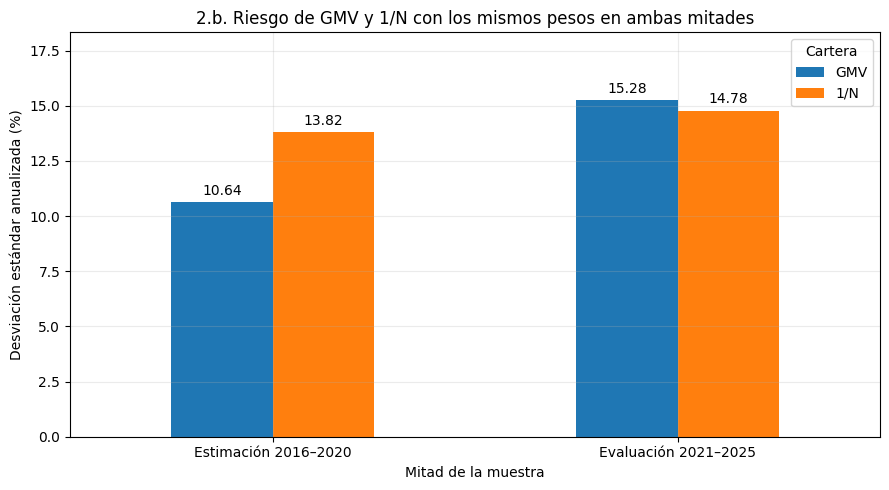

In [13]:
p2_retornos_estimacion = p2_estimacion @ p2_pesos
p2_retornos_evaluacion = p2_evaluacion @ p2_pesos
p2_vol_anual = pd.DataFrame({
    "Estimación 2016–2020": p2_retornos_estimacion.std(ddof=1) * np.sqrt(12),
    "Evaluación 2021–2025": p2_retornos_evaluacion.std(ddof=1) * np.sqrt(12),
})
p2_vol_anual.index.name = "cartera"

# Comprobación independiente con w' Sigma w en cada mitad.
p2_cov_evaluacion = p2_evaluacion.cov(ddof=1)
for nombre in p2_pesos:
    w = p2_pesos[nombre].to_numpy()
    assert np.isclose(p2_vol_anual.loc[nombre, "Estimación 2016–2020"], np.sqrt(12 * w @ p2_S @ w))
    assert np.isclose(p2_vol_anual.loc[nombre, "Evaluación 2021–2025"],
                      np.sqrt(12 * w @ p2_cov_evaluacion.to_numpy() @ w))
assert p2_vol_anual.loc["GMV", "Estimación 2016–2020"] <= p2_vol_anual.loc["1/N", "Estimación 2016–2020"] + 1e-12

print("Desviaciones estándar ANUALIZADAS, en porcentaje:")
display((100 * p2_vol_anual).round(4))
p2_diferencia_pp = (p2_vol_anual.loc["GMV"] - p2_vol_anual.loc["1/N"]) * 100
display(p2_diferencia_pp.rename("GMV_menos_1_N_en_puntos_porcentuales").to_frame())

ax = (100 * p2_vol_anual.T).plot.bar(rot=0, figsize=(9, 5))
ax.set(xlabel="Mitad de la muestra", ylabel="Desviación estándar anualizada (%)",
       title="2.b. Riesgo de GMV y 1/N con los mismos pesos en ambas mitades")
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.2f", padding=3)
ax.legend(title="Cartera")
ax.set_ylim(0, 100 * p2_vol_anual.to_numpy().max() * 1.2)
plt.tight_layout()
plt.show()

In [14]:
display(Markdown(f"""
**2.b. Observación.** En la primera mitad, la volatilidad anualizada de GMV es
**{p2_vol_anual.loc['GMV', 'Estimación 2016–2020']:.4%}**, frente a
**{p2_vol_anual.loc['1/N', 'Estimación 2016–2020']:.4%}** para 1/N. Esto es esperable por construcción:
GMV minimiza la varianza usando precisamente la matriz de covarianzas de esa mitad, y 1/N es una alternativa
factible dentro del mismo problema.

En la evaluación, sin cambiar los pesos, GMV presenta una volatilidad de
**{p2_vol_anual.loc['GMV', 'Evaluación 2021–2025']:.4%}**, frente a
**{p2_vol_anual.loc['1/N', 'Evaluación 2021–2025']:.4%}** de 1/N. GMV supera a 1/N en
**{p2_diferencia_pp['Evaluación 2021–2025']:.4f} puntos porcentuales de volatilidad**: su ventaja dentro de muestra
no se mantiene fuera de muestra en este período. Esto ilustra los problemas de error de estimación e
inestabilidad de covarianzas estudiados en clases. Estos dos resultados por sí solos no permiten separar
cuánto corresponde a cada causa ni demostrar significancia estadística de la diferencia.
"""))


**2.b. Observación.** En la primera mitad, la volatilidad anualizada de GMV es
**10.6390%**, frente a
**13.8197%** para 1/N. Esto es esperable por construcción:
GMV minimiza la varianza usando precisamente la matriz de covarianzas de esa mitad, y 1/N es una alternativa
factible dentro del mismo problema.

En la evaluación, sin cambiar los pesos, GMV presenta una volatilidad de
**15.2756%**, frente a
**14.7809%** de 1/N. GMV supera a 1/N en
**0.4946 puntos porcentuales de volatilidad**: su ventaja dentro de muestra
no se mantiene fuera de muestra en este período. Esto ilustra los problemas de error de estimación e
inestabilidad de covarianzas estudiados en clases. Estos dos resultados por sí solos no permiten separar
cuánto corresponde a cada causa ni demostrar significancia estadística de la diferencia.


In [15]:
display(Markdown(r"""
## 2.c. Recomendación al cliente y límites de la conclusión

**Con esta evidencia y sin más información del cliente, recomendaría 1/N como punto de partida**, por su
simplicidad, transparencia y ausencia de ventas cortas. Además, durante los 60 meses de evaluación tuvo
una volatilidad ligeramente menor que la GMV estimada en la primera mitad. Evita depender de la estimación
de una matriz de covarianzas para decidir los pesos, aunque sigue necesitando rebalanceo y tiene riesgo de mercado.

La decisión real debe considerar el objetivo del cliente, su horizonte y tolerancia al riesgo, límites de
posición, capacidad de vender corto, costos, liquidez e impuestos. La comparación no demuestra que las
comisiones efectivas de una estrategia sean menores: no se han calculado costos ni rotación. Si su objetivo
fuera minimizar riesgo sujeto a restricciones reales, habría que especificarlas y evaluar esa nueva solución.

**Con estos resultados no puedo afirmar**:

- Que 1/N tendrá siempre menos riesgo que GMV o que será superior en otra muestra o en el futuro.
- Que 1/N tendrá mayor rentabilidad, Sharpe o utilidad para el cliente: aquí se compara volatilidad y no
  se utiliza una tasa libre de riesgo ni se estima una función de utilidad.
- Que la diferencia de volatilidad de evaluación sea estadísticamente significativa: no se hizo ese contraste.
- Que GMV sea inútil o que MPT sea falsa. La solución sí minimiza la varianza de la primera mitad;
  lo que falla en esta evaluación es trasladar automáticamente esa ventaja a covarianzas futuras desconocidas.
- Que los resultados sean netos de costos, que eliminen el riesgo de mercado o que una sola división 60/60
  baste para establecer superioridad general. Harían falta más ventanas de evaluación y supuestos de implementación.

Esta es una recomendación condicionada por la evidencia presentada; no una garantía de desempeño futuro.
"""))


## 2.c. Recomendación al cliente y límites de la conclusión

**Con esta evidencia y sin más información del cliente, recomendaría 1/N como punto de partida**, por su
simplicidad, transparencia y ausencia de ventas cortas. Además, durante los 60 meses de evaluación tuvo
una volatilidad ligeramente menor que la GMV estimada en la primera mitad. Evita depender de la estimación
de una matriz de covarianzas para decidir los pesos, aunque sigue necesitando rebalanceo y tiene riesgo de mercado.

La decisión real debe considerar el objetivo del cliente, su horizonte y tolerancia al riesgo, límites de
posición, capacidad de vender corto, costos, liquidez e impuestos. La comparación no demuestra que las
comisiones efectivas de una estrategia sean menores: no se han calculado costos ni rotación. Si su objetivo
fuera minimizar riesgo sujeto a restricciones reales, habría que especificarlas y evaluar esa nueva solución.

**Con estos resultados no puedo afirmar**:

- Que 1/N tendrá siempre menos riesgo que GMV o que será superior en otra muestra o en el futuro.
- Que 1/N tendrá mayor rentabilidad, Sharpe o utilidad para el cliente: aquí se compara volatilidad y no
  se utiliza una tasa libre de riesgo ni se estima una función de utilidad.
- Que la diferencia de volatilidad de evaluación sea estadísticamente significativa: no se hizo ese contraste.
- Que GMV sea inútil o que MPT sea falsa. La solución sí minimiza la varianza de la primera mitad;
  lo que falla en esta evaluación es trasladar automáticamente esa ventaja a covarianzas futuras desconocidas.
- Que los resultados sean netos de costos, que eliminen el riesgo de mercado o que una sola división 60/60
  baste para establecer superioridad general. Harían falta más ventanas de evaluación y supuestos de implementación.

Esta es una recomendación condicionada por la evidencia presentada; no una garantía de desempeño futuro.


In [16]:
import json
import zipfile

assert set(p2_pesos.index) == set(ACCIONES) and "SPY" not in p2_pesos.index
assert len(p2_estimacion) == len(p2_evaluacion) == 60
assert np.allclose(p2_w_gmv.sum(), 1) and np.allclose(p2_w_igual.sum(), 1)
assert np.isfinite(p2_pesos.to_numpy()).all() and np.isfinite(p2_vol_anual.to_numpy()).all()
# Las dos dominancias utilizadas en el resumen de la pregunta 1 están comprobadas en la tabla.
assert any((fila["dominante"], fila["dominada"]) == ("JPM", "XOM") for fila in filas_dominancia)
assert any((fila["dominante"], fila["dominada"]) == ("NEE", "HD") for fila in filas_dominancia)

entrega = Path("resultados_prueba2")
entrega.mkdir(exist_ok=True)
for nombre, tabla in tablas.items():
    tabla.to_csv(entrega / f"p1_{nombre}.csv", encoding="utf-8-sig")
p2_tablas = {
    "periodos": p2_periodos,
    "covarianzas_estimacion_mensuales": p2_cov_estimacion,
    "pesos_decimales": p2_pesos,
    "pesos_porcentajes": 100 * p2_pesos,
    "volatilidades_anuales_decimales": p2_vol_anual,
    "volatilidades_anuales_porcentajes": 100 * p2_vol_anual,
    "retornos_carteras_estimacion": p2_retornos_estimacion,
    "retornos_carteras_evaluacion": p2_retornos_evaluacion,
}
for nombre, tabla in p2_tablas.items():
    tabla.to_csv(entrega / f"p2_{nombre}.csv", encoding="utf-8-sig")
parametros = {
    "unico_archivo_datos": NOMBRE_CSV,
    "revision_datos": REVISION,
    "sha256_datos": HASH_CSV,
    "acciones": ACCIONES,
    "mercado_pregunta1": "SPY",
    "tasa_libre_de_riesgo_utilizada": False,
    "anualizacion": {"media": "mensual * 12", "desviacion": "mensual * sqrt(12)", "varianza": "mensual * 12"},
    "divisor_varianzas": "T-1, incluida la varianza residual de pregunta 1",
    "estimacion_pregunta2": {"inicio": "2016-01", "fin": "2020-12", "meses": 60},
    "evaluacion_pregunta2": {"inicio": "2021-01", "fin": "2025-12", "meses": 60},
    "restriccion_GMV": "suma de pesos = 1; sin limites de posicion; ventas cortas permitidas",
    "n_posiciones_cortas_GMV": len(p2_cortas),
    "rebalanceo": "mensual; mismos vectores de pesos en ambas mitades",
    "costos_incluidos": False,
}
(entrega / "parametros.json").write_text(json.dumps(parametros, ensure_ascii=False, indent=2), encoding="utf-8")
with zipfile.ZipFile("resultados_prueba2.zip", "w", zipfile.ZIP_DEFLATED) as archivo_zip:
    for archivo in sorted(entrega.iterdir()):
        if archivo.is_file():
            archivo_zip.write(archivo, arcname=archivo.name)
print("Controles de las dos preguntas: OK.")
print("Único insumo: Prueba2_2026S2_acciones.csv. SPY excluido de las carteras. Sin rf.")
print("Exportadas", len(tablas) + len(p2_tablas), "tablas y parámetros a resultados_prueba2.zip.")

Controles de las dos preguntas: OK.
Único insumo: Prueba2_2026S2_acciones.csv. SPY excluido de las carteras. Sin rf.
Exportadas 17 tablas y parámetros a resultados_prueba2.zip.
